In [21]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import medfilt
from tqdm import tqdm

In [22]:
def slow_mean(stack, valid):
    n = 0
    out = np.zeros(stack.shape[1:])
    for i in tqdm(list(range(stack.shape[0]))):
        if valid[i]:
            out += stack[i, ...]
            n += 1
    return out / n

In [2]:
proposal_number = 101927227  # noqa
run = 119  # noqa

In [3]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='/jungfrau1M/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)

In [4]:
h5.keys()

<KeysViewHDF5 ['Sums', 'UserDataCfg', 'ai', 'damage', 'diodeGon', 'enc', 'epics', 'epicsOnce', 'epicsUser', 'epix_6', 'epix_6_env', 'event_time', 'evr', 'fiducials', 'gas_detector', 'ipm2', 'ipm4', 'ipm5', 'jungfrau1M', 'lightStatus', 'phase_cav', 'scan', 'snd_dio', 'tt']>

In [5]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

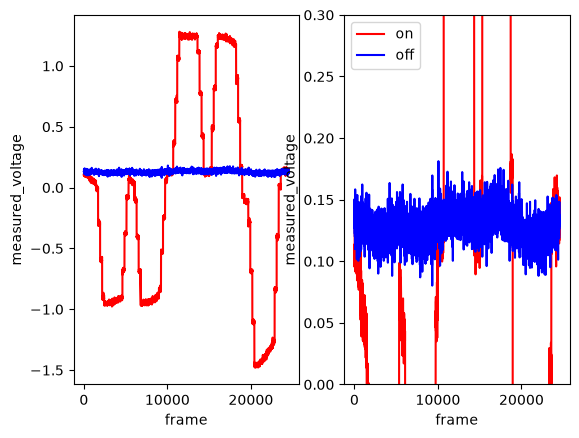

In [6]:
on_meta = metadata[metadata['laser_on']]
off_meta = metadata[~metadata['laser_on']]
fig, axs = plt.subplots(1, 2)
for ax in axs:
    ax.plot(on_meta['measured_voltage'], label='on', color='red')
    ax.plot(off_meta['measured_voltage'], label='off', color='blue')
    ax.set_xlabel('frame')
    ax.set_ylabel('measured_voltage')
axs[1].set_ylim(bottom=0.0, top=0.3)
plt.legend()
plt.show()

In [7]:
rois = [
    (slice(50,100), slice(150,220)), # whole ROI, bto and ctr and diffuse
    (slice(68, 78), slice(185, 195)), # ctr peak dominated
    (slice(68, 78), slice(165, 175)), # bto peak (clipped slightly)
    (slice(50,65), slice(185,195)), #diffuse area above the ctr
    (slice(50,65), slice(173,183)), # estimated satellite region
    (slice(50,100), slice(50,100)) # area far from peaks
]

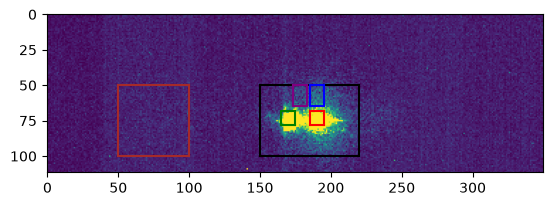

In [8]:
xcs.plot_detector_image(h5, h5dict, samplerate=100)
roi_colors = ['black', 'red', 'green', 'blue', 'purple', 'brown']
for i, roi in enumerate(rois):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

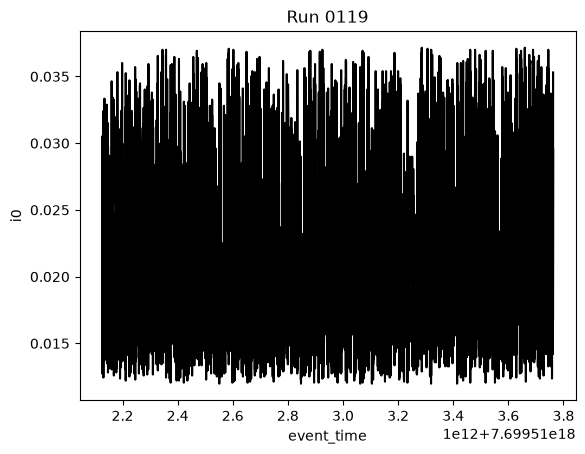

In [9]:
xcs.plot_i0_vs_time(metadata, valid).show()

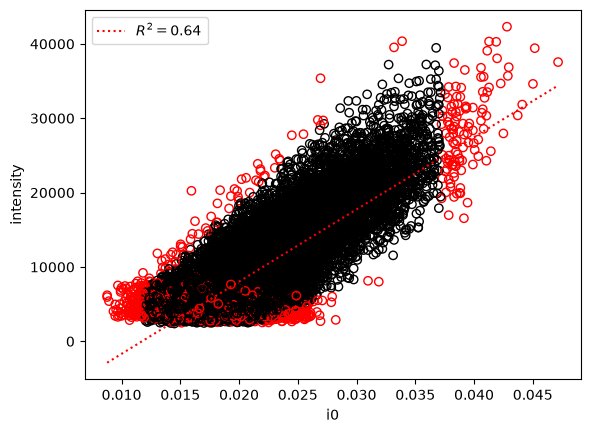

In [10]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

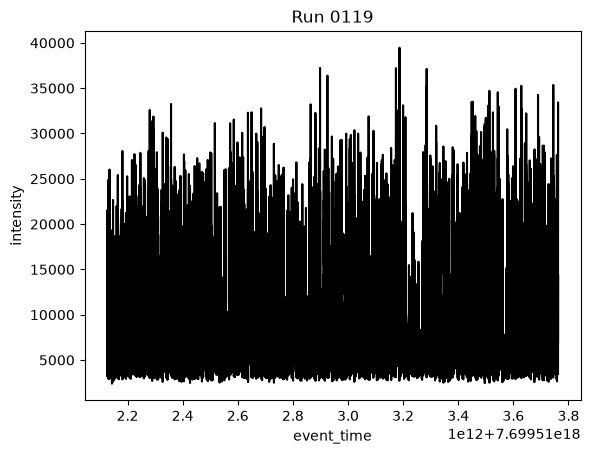

In [11]:
xcs.plot_intensity_vs_time(metadata, valid).show()

In [12]:
delays = h5[h5dict.delay][...]
diff = np.diff(delays)
u_diffs, counts = np.unique(diff, return_counts=True)
typical_dt = u_diffs[u_diffs > 0][np.argmax(counts[u_diffs > 0])]
print(f'{typical_dt=:0.2f}')

typical_dt=168.07


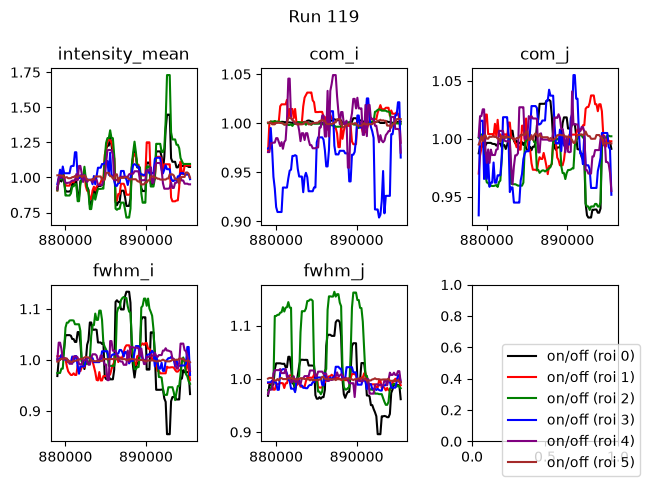

In [13]:

fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'on/off (roi {j})' if i == 0 else None
        ax.plot(trxrd.index, medfilt(trxrd[f'on_{tag}']/trxrd[f'off_{tag}'], 5), color=color, linestyle='-', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()

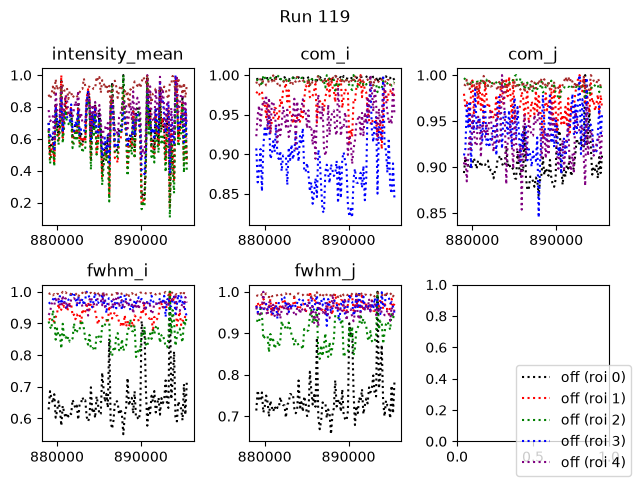

In [14]:


def normalize(a):
    return a / np.amax(a)


fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'off (roi {j})' if j == i else None
        ax.plot(trxrd.index, normalize(trxrd[f'off_{tag}']), color=color, linestyle=':', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()

In [23]:
voltage_high = h5[h5dict.measured_voltage][...] > 1.0
laser_on = h5[h5dict.laser_on][...].astype(bool)
n_on = np.count_nonzero(voltage_high)
n_off = np.count_nonzero((~voltage_high) & (~laser_on))
high_and_on = (voltage_high) & (laser_on)
off = (~voltage_high) & (~laser_on)
stack = h5[h5dict.stack]

In [24]:
mean_on = slow_mean(stack, high_and_on)
mean_off = slow_mean(stack, off)

100%|██████████| 24543/24543 [00:00<00:00, 31984.48it/s]


In [25]:
diff = mean_on / mean_off - 1.0

/lscratch/bfichera/tmp/ipykernel_3740279/4214895067.py:1: RuntimeWarning: invalid value encountered in divide
  diff = mean_on / mean_off - 1.0


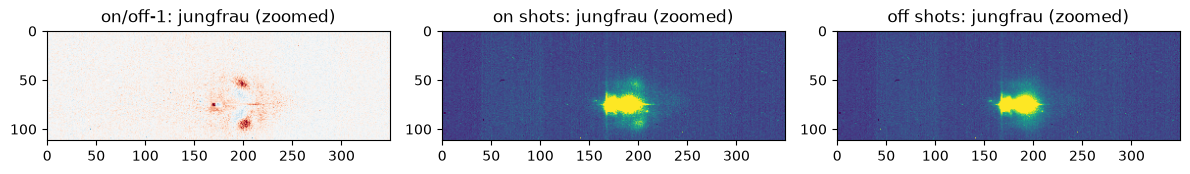

In [30]:
fig, axd = plt.subplot_mosaic([['diff', 'on', 'off']], figsize=(12, 12))
axd['diff'].imshow(diff, cmap='RdBu_r', vmin=-1.0, vmax=1.0)
axd['on'].imshow(mean_on, vmin=0.0, vmax=0.6)
axd['off'].imshow(mean_off, vmin=0.0, vmax=0.6)

axd['diff'].set_title('on/off-1: jungfrau (zoomed)')
axd['on'].set_title('on shots: jungfrau (zoomed)')
axd['off'].set_title('off shots: jungfrau (zoomed)')

fig.tight_layout()

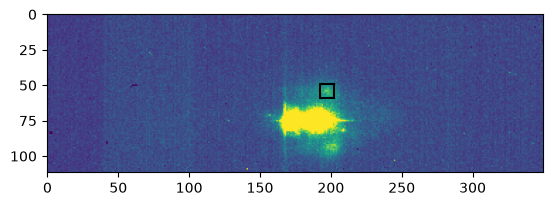

In [35]:
roi_sl = slice(49, 59), slice(192, 202)
plt.imshow(mean_on, vmin=0.0, vmax=0.6)
roi_colors = ['black', 'red', 'green', 'blue', 'purple', 'brown']
for i, roi in enumerate([roi_sl]):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

In [39]:
roi_sl_int_vs_frame = np.sum(stack[:, *roi_sl], axis=(-1, -2))
time_vs_frame = h5[h5dict.delay][...]

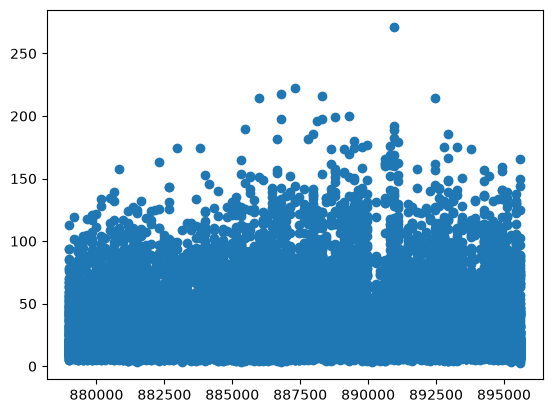

In [40]:
plt.scatter(time_vs_frame, roi_sl_int_vs_frame)
plt.show()